# Stacked gravitational potential around halos: Gadget-4 vs pkdgrav3

Mean peculiar potential $\langle\phi\rangle(r)$ (physical, (km/s)$^2$) in shells of comoving distance $r$ (Mpc/h) from
host-halo centres, stacked in bins of $M_{\rm vir}$, for the Gadget-4 and pkdgrav3 runs started from the same ICs
(Sahyadri default settings, pawna). Made by `scripts/gadget_pkdgrav3_compare/halo_potential_profile.py`: only the stacks
are stored (no per-halo profiles).

* shaded band: $\pm$ the standard deviation of $\phi$ over all (halo, particle) pairs in the shell (`stack_std`)
* error bars: jackknife error of the mean over $3^3$ sub-cubes of halo centres (`stack_err`)
* each code uses its own consistent-trees halos (Rockstar `.list` where there is none: 32$^3$); pkdgrav3 without its
  softened self-potential and aligned to Gadget's zero point by the particle median offset (`--offset`)
* `pkc`: the same pkdgrav3 run from the compressed `.pkc` snapshot (potential quantised to the `.pkc` step)

Set `RUNS` to the comparison directories (copied from pawna, see the report) and run all cells.

In [1]:
import glob, os, re
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

HERE = os.path.abspath('.')
RUNS = {'256^3': os.path.join(HERE, 'data', 'pkd256_vs_gadget256_r1', 'profiles'),
        '32^3': os.path.join(HERE, 'data', 'pkd32_vs_gadget32_r1', 'profiles')}
FIGS = os.path.join(HERE, 'figs')
os.makedirs(FIGS, exist_ok=True)
STYLE = {'gadget': dict(color='#1f5fa8', label='Gadget-4'),
         'pkd': dict(color='#c8553d', label='pkdgrav3 (HDF5)'),
         'pkc': dict(color='#333333', label='pkdgrav3 (.pkc)', ls='--')}

def load(d):
    # <kind>_out<i>[_lin|_vol|_vol_lin].npz -> P[i]['<kind>[_tag]']; shells with < MINPAIR points (and, volume-weighted,
    # shells inside one grid cell) are masked
    out = {}
    for f in sorted(glob.glob(os.path.join(d, '*_out*.npz'))):
        kind, i, tag = re.match(r'([a-z]+)_out(\d+)(_\w+)?\.npz', os.path.basename(f)).groups()
        s = dict(np.load(f, allow_pickle=True))
        bad = ~(s['npair'] >= MINPAIR)
        if str(s.get('weight', 'particle')) == 'volume':
            # grid points: shells inside one grid cell (nbar^(-1/3)) only see the interpolation, not the field
            bad |= s['r_edges'][1:] < float(s['nbar'])**(-1 / 3)
        for k in ('stack_mean', 'stack_std', 'stack_err', 'r_mean', 'delta_hm', 'delta_hm_err'):
            s[k] = np.where(bad, np.nan, s[k])
        for k in ('jk_n', 'jk_s', 'jk_s2'):
            s[k] = np.where(bad[None], 0, s[k])
        out.setdefault(int(i), {})[kind + (tag or '')] = s
    return out

MINPAIR = 50

def jk_pair(g, p, b, what='phi'):
    # Paired jackknife over the same 3^3 sub-cubes of halo centres: difference pkd - Gadget of the shell mean
    # potential ('phi') or of 1 + xi_hm ('xi', as a ratio pkd / Gadget - 1). Both runs share the large-scale
    # structure, so the paired error of the difference is much smaller than the two errors added in quadrature.
    def est(s, keep):
        n, sm, nh = s['jk_n'][keep, b].sum(0), s['jk_s'][keep, b].sum(0), s['jk_nh'][keep, b].sum()
        if what == 'phi':
            return sm / n
        vol = 4 / 3 * np.pi * np.diff(s['r_edges']**3)
        return n / s['frac'] / (nh * s['nbar'] * vol)
    nreg = g['jk_n'].shape[0]
    allr = np.ones(nreg, bool)
    f = (lambda a, c: c - a) if what == 'phi' else (lambda a, c: c / a - 1)
    full = f(est(g, allr), est(p, allr))
    reg = [i for i in range(nreg) if g['jk_nh'][i, b] > 0 or p['jk_nh'][i, b] > 0]
    if len(reg) < 2:
        return full, np.full_like(full, np.nan)
    sub = []
    for i in reg:
        k = allr.copy(); k[i] = False
        sub.append(f(est(g, k), est(p, k)))
    sub = np.array(sub)
    return full, np.sqrt((len(reg) - 1) / len(reg) * np.nansum((sub - np.nanmean(sub, 0))**2, 0))

P = {k: load(v) for k, v in RUNS.items() if os.path.isdir(v)}
for k, v in P.items():
    print(k, 'outputs', sorted(v), '; z =', [round(float(v[i]['gadget']['z']), 3) for i in sorted(v)])

256^3 outputs [19, 46, 64, 100] ; z = [2.956, 0.997, 0.499, 0.0]
32^3 outputs [19, 46, 64, 100] ; z = [2.956, 0.997, 0.499, 0.0]


## Mean potential and its scatter, per mass bin, for every output

/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:42: RuntimeWarning: invalid value encountered in divide
  return sm / n
/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:57: RuntimeWarning: Mean of empty slice
  return full, np.sqrt((len(reg) - 1) / len(reg) * np.nansum((sub - np.nanmean(sub, 0))**2, 0))


/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:42: RuntimeWarning: invalid value encountered in divide
  return sm / n
/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:57: RuntimeWarning: Mean of empty slice
  return full, np.sqrt((len(reg) - 1) / len(reg) * np.nansum((sub - np.nanmean(sub, 0))**2, 0))


/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:42: RuntimeWarning: invalid value encountered in divide
  return sm / n
/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:57: RuntimeWarning: Mean of empty slice
  return full, np.sqrt((len(reg) - 1) / len(reg) * np.nansum((sub - np.nanmean(sub, 0))**2, 0))


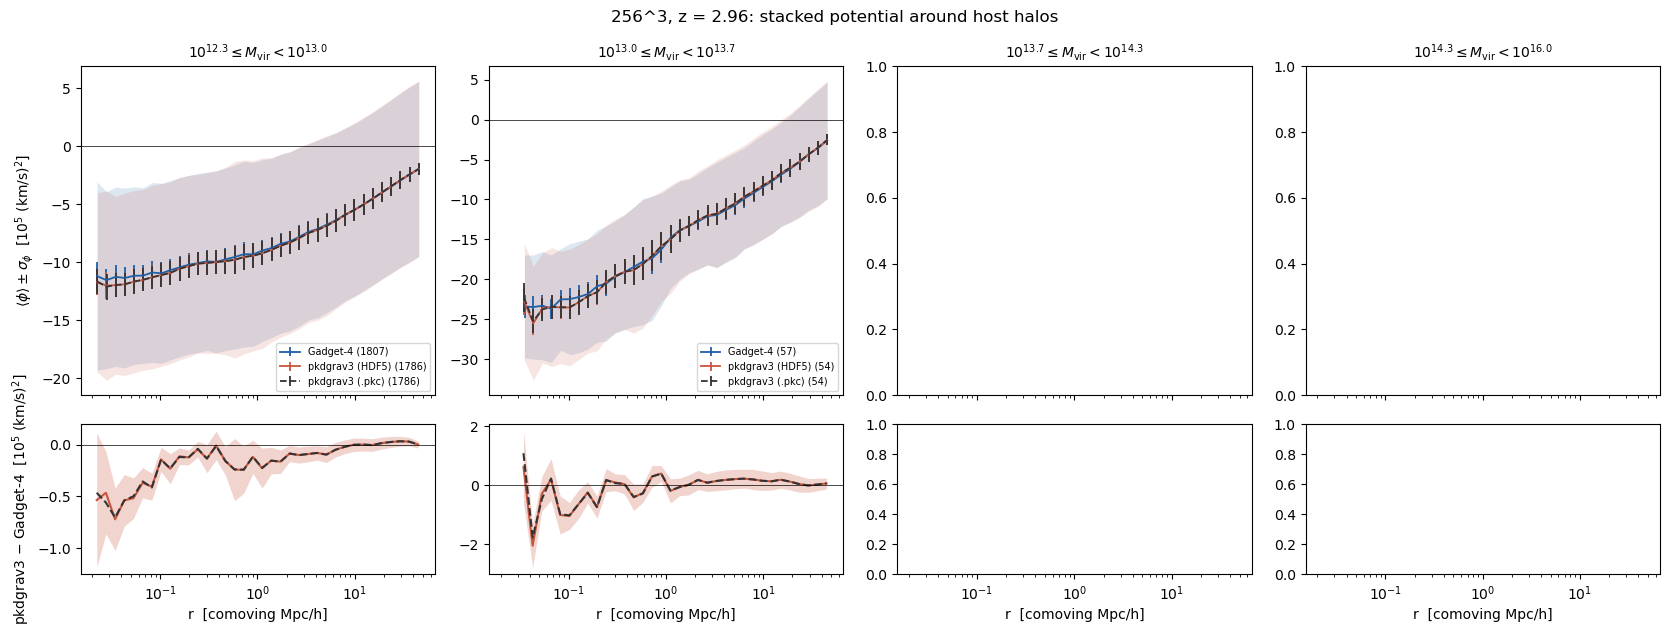

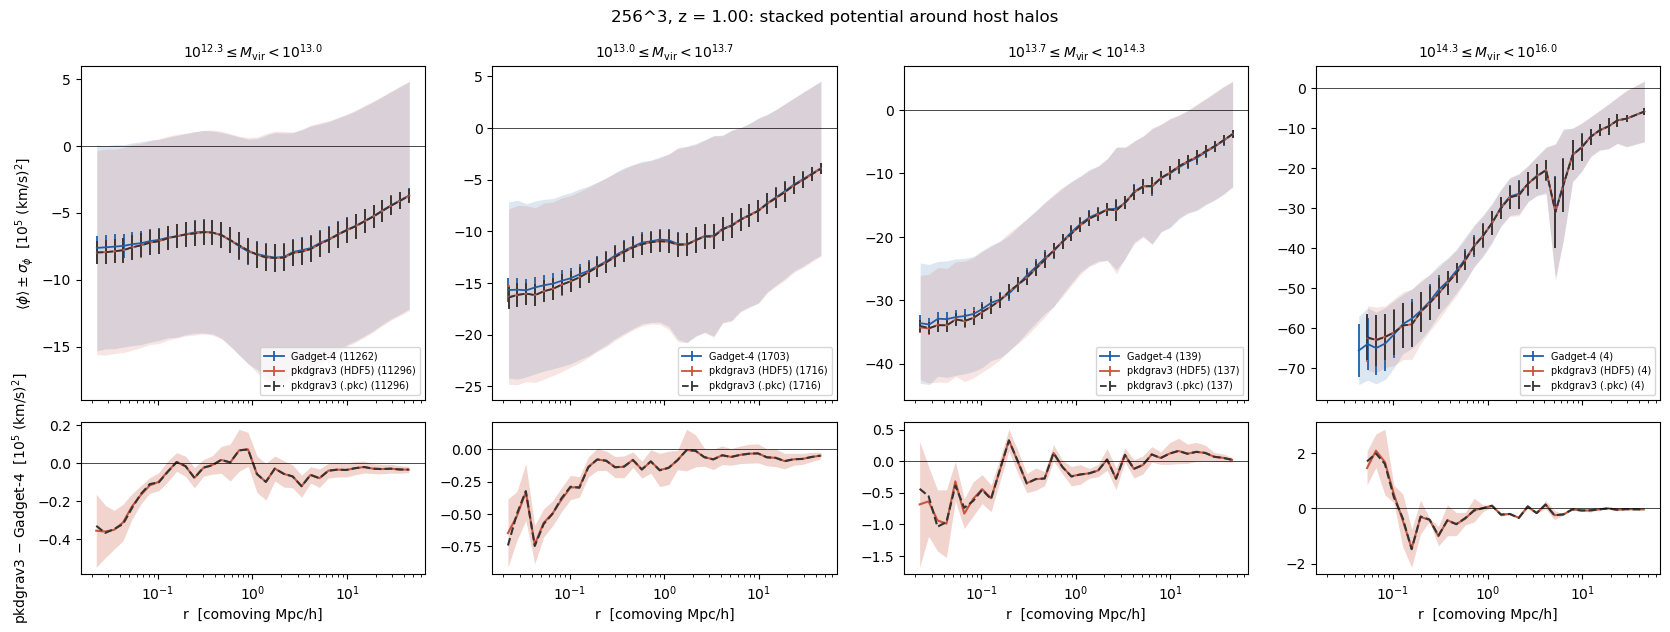

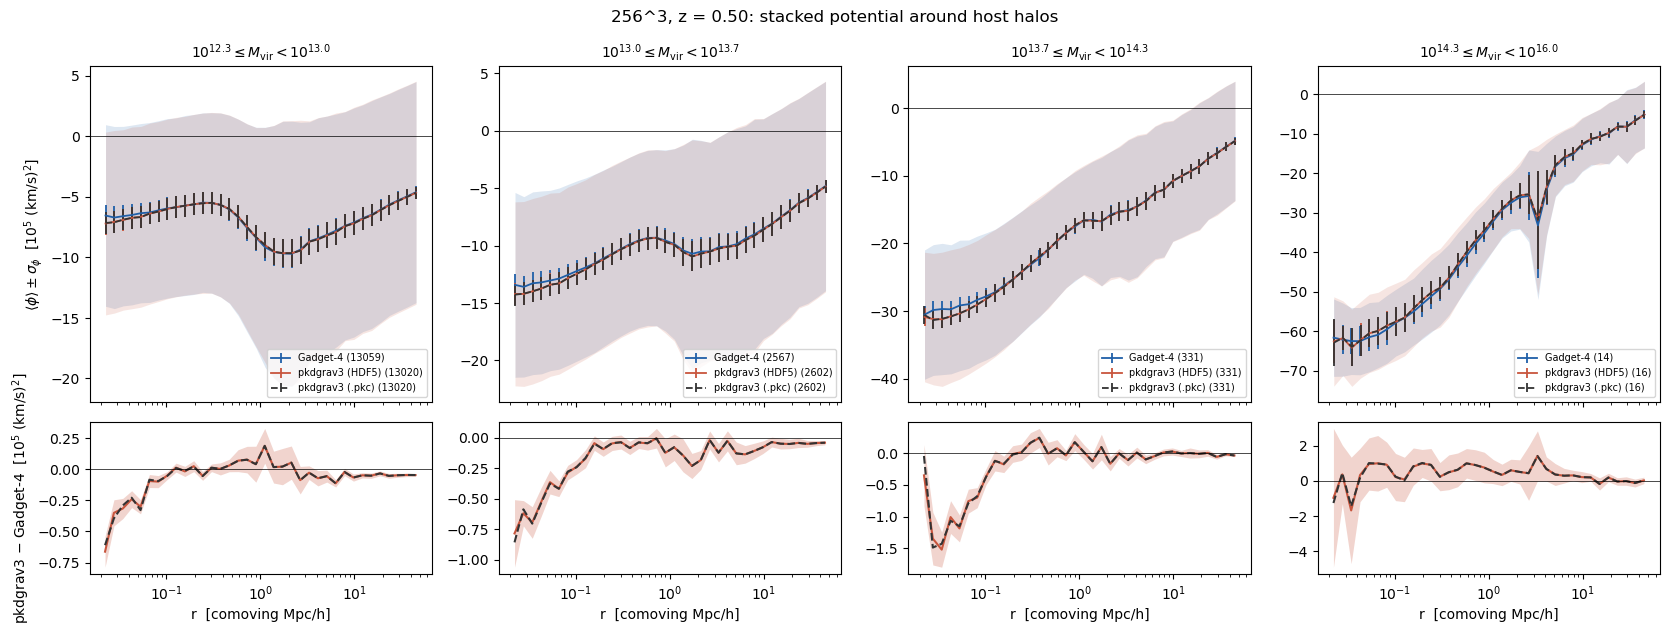

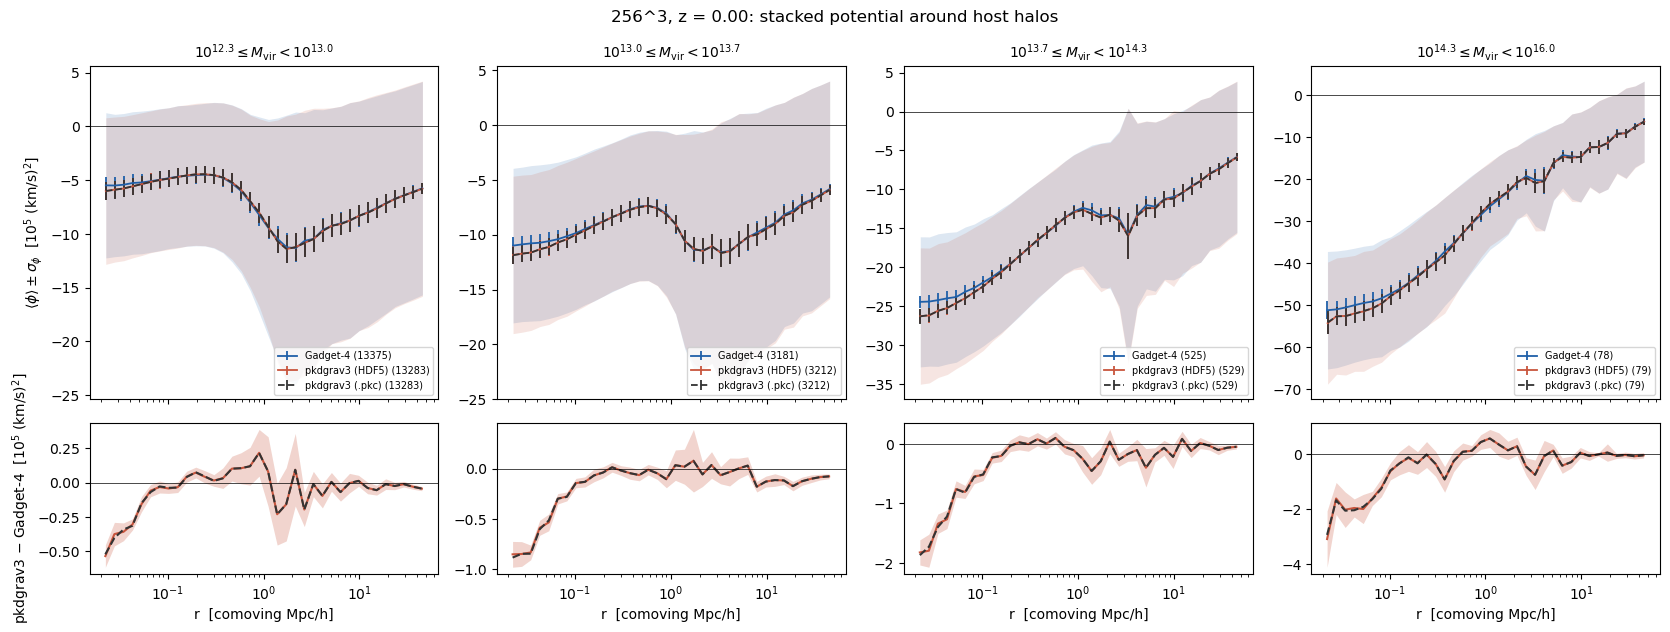

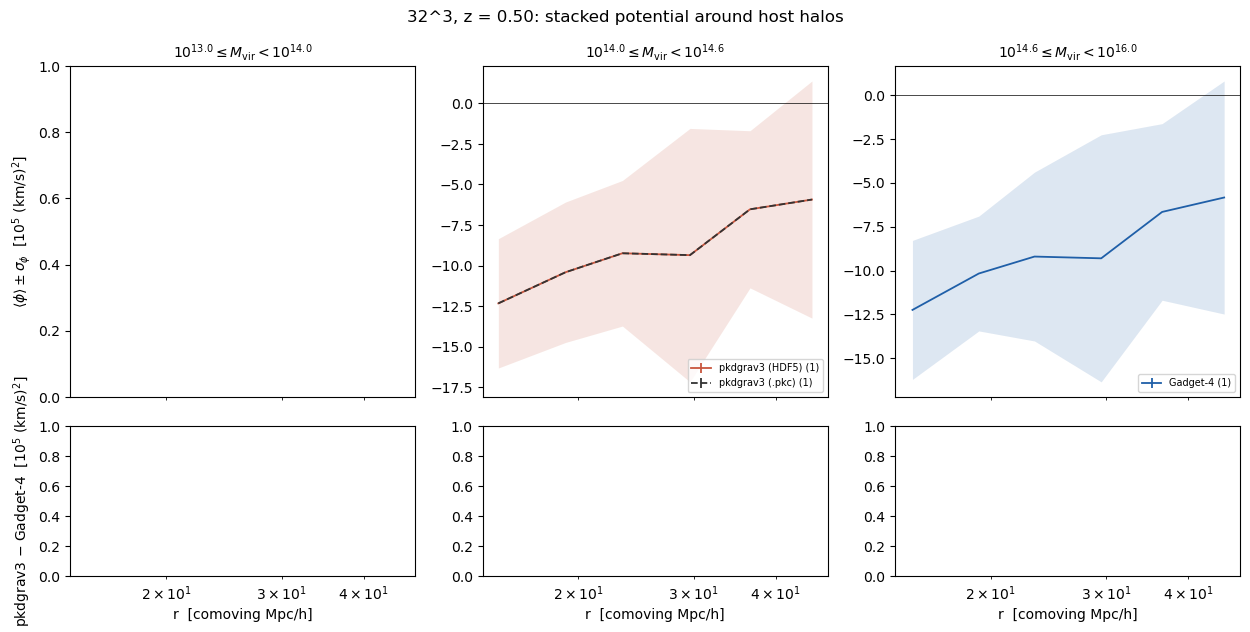

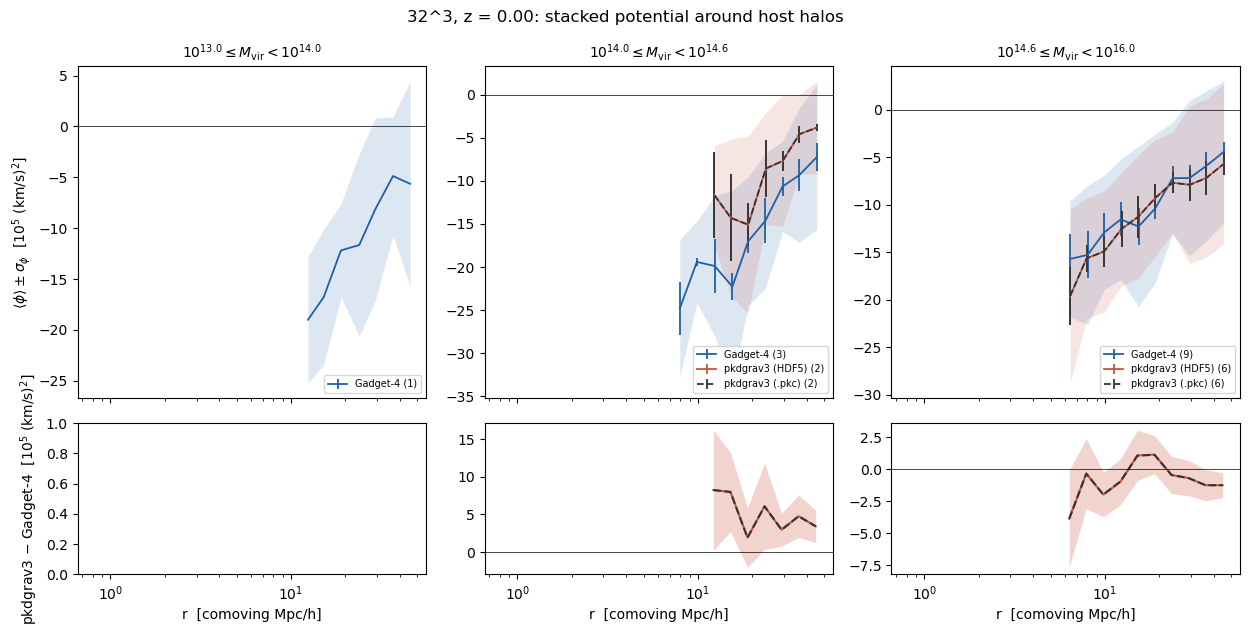

In [2]:
def mlabel(lo, hi):
    f = lambda m: '10^{%.1f}' % np.log10(m)
    return '$%s \\leq M_{\\rm vir} < %s$' % (f(lo), f(hi))

def plot_output(run, i, save=True):
    S = P[run][i]
    g = S['gadget']
    me, nb = g['m_edges'], len(g['n_halos'])
    fig, ax = plt.subplots(2, nb, figsize=(4.2 * nb, 6.4), sharex=True, squeeze=False,
                           gridspec_kw=dict(height_ratios=[2.2, 1]))
    for b in range(nb):
        a0, a1 = ax[0, b], ax[1, b]
        for kind in ('gadget', 'pkd', 'pkc'):
            if kind not in S or S[kind]['n_halos'][b] == 0:
                continue
            s, st = S[kind], STYLE[kind]
            r = s['r_mean'][b]
            m, sd, e = s['stack_mean'][b] / 1e5, s['stack_std'][b] / 1e5, s['stack_err'][b] / 1e5
            a0.errorbar(r, m, e, color=st['color'], ls=st.get('ls', '-'), lw=1.3, capsize=0,
                        label='%s (%d)' % (st['label'], s['n_halos'][b]))
            if kind != 'pkc':
                a0.fill_between(r, m - sd, m + sd, color=st['color'], alpha=0.15, lw=0)
            if kind != 'gadget' and g['n_halos'][b] > 0:
                dm, de = jk_pair(g, s, b)
                a1.plot(g['r_mid'], dm / 1e5, color=st['color'], ls=st.get('ls', '-'))
                if kind == 'pkd':
                    a1.fill_between(g['r_mid'], (dm - de) / 1e5, (dm + de) / 1e5, color=st['color'], alpha=0.25, lw=0)
        a0.axhline(0, color='k', lw=0.5); a1.axhline(0, color='k', lw=0.5)
        a0.set_title(mlabel(me[b], me[b + 1]), fontsize=10)
        a1.set_xscale('log'); a1.set_xlabel('r  [comoving Mpc/h]')
        if a0.get_legend_handles_labels()[0]:
            a0.legend(fontsize=7, loc='lower right')
    ax[0, 0].set_ylabel(r'$\langle\phi\rangle \pm \sigma_\phi$  [$10^5$ (km/s)$^2$]')
    ax[1, 0].set_ylabel(r'pkdgrav3 $-$ Gadget-4  [$10^5$ (km/s)$^2$]')
    fig.suptitle('%s, z = %.2f: stacked potential around host halos' % (run, float(g['z'])))
    fig.tight_layout()
    if save:
        fig.savefig(os.path.join(FIGS, 'stack_%s_out%03d.pdf' % (run.replace('^3', ''), i)))
    return fig

for run in P:
    for i in sorted(P[run]):
        if any(P[run][i]['gadget']['n_halos']):
            plot_output(run, i)
plt.show()

## Difference of the mean potential in units of the shell scatter, all outputs

$\Delta\langle\phi\rangle/\sigma_\phi$ = (pkdgrav3 $-$ Gadget-4) / Gadget-4 `stack_std`; the band is the paired jackknife error of the difference (same sub-cubes for both codes). (A ratio of the means is ill-defined where $\langle\phi\rangle$ crosses zero at large $r$.)

/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:42: RuntimeWarning: invalid value encountered in divide
  return sm / n
/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:57: RuntimeWarning: Mean of empty slice
  return full, np.sqrt((len(reg) - 1) / len(reg) * np.nansum((sub - np.nanmean(sub, 0))**2, 0))


/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:42: RuntimeWarning: invalid value encountered in divide
  return sm / n
/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:57: RuntimeWarning: Mean of empty slice
  return full, np.sqrt((len(reg) - 1) / len(reg) * np.nansum((sub - np.nanmean(sub, 0))**2, 0))


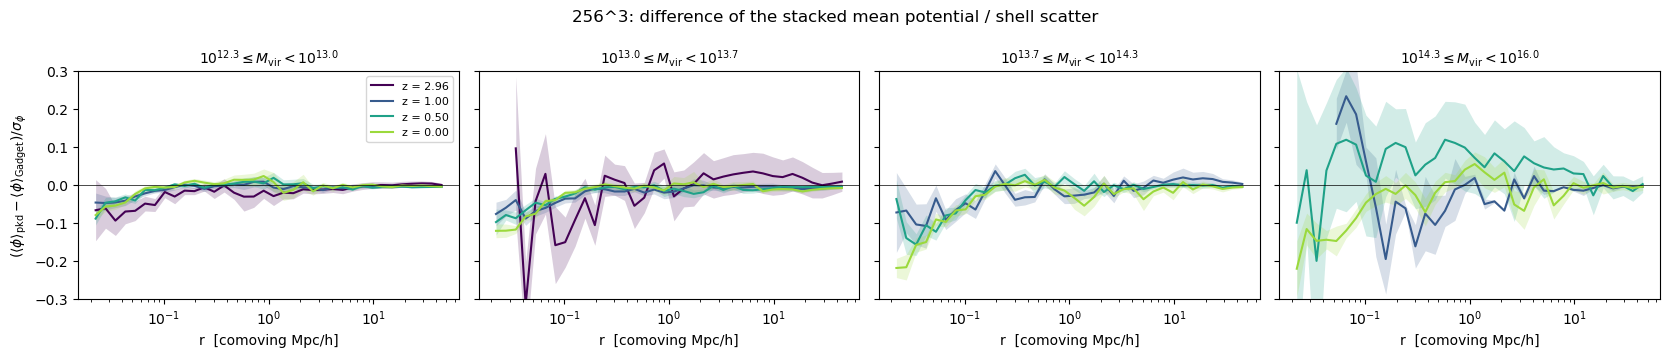

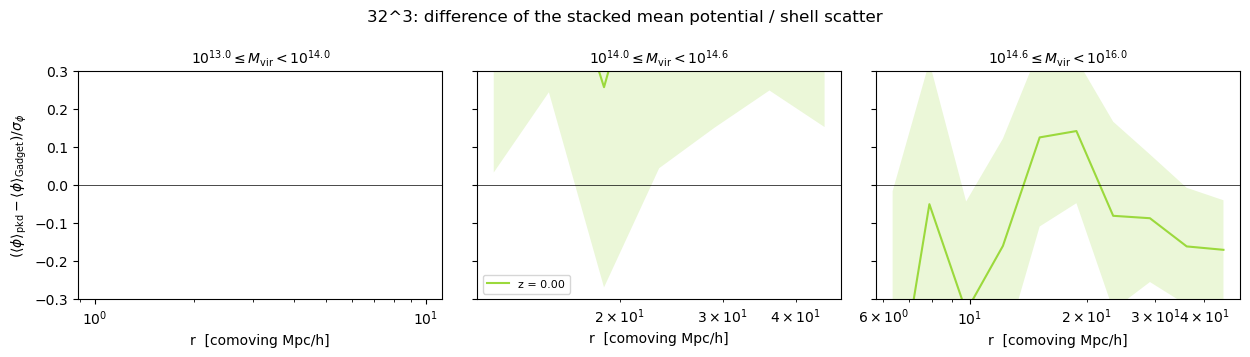

In [3]:
def plot_relative(run, save=True):
    outs = [i for i in sorted(P[run]) if any(P[run][i]['gadget']['n_halos'])]
    g0 = P[run][outs[-1]]['gadget']; nb = len(g0['n_halos'])
    fig, ax = plt.subplots(1, nb, figsize=(4.2 * nb, 3.6), sharey=True, squeeze=False)
    cols = plt.cm.viridis(np.linspace(0, 0.85, len(outs)))
    for c, i in zip(cols, outs):
        g, p = P[run][i]['gadget'], P[run][i]['pkd']
        for b in range(nb):
            if g['n_halos'][b] == 0 or p['n_halos'][b] == 0:
                continue
            d, e = jk_pair(g, p, b)
            rel, err = d / g['stack_std'][b], e / g['stack_std'][b]
            ax[0, b].plot(g['r_mid'], rel, color=c, label='z = %.2f' % float(g['z']))
            ax[0, b].fill_between(g['r_mid'], rel - err, rel + err, color=c, alpha=0.2, lw=0)
    for b in range(nb):
        ax[0, b].axhline(0, color='k', lw=0.5); ax[0, b].set_xscale('log')
        ax[0, b].set_title(mlabel(g0['m_edges'][b], g0['m_edges'][b + 1]), fontsize=10)
        ax[0, b].set_xlabel('r  [comoving Mpc/h]')
    ax[0, 0].set_ylabel(r'$(\langle\phi\rangle_{\rm pkd} - \langle\phi\rangle_{\rm Gadget}) / \sigma_\phi$')
    ax[0, 0].set_ylim(-0.3, 0.3)
    for a in ax[0]:
        if a.get_legend_handles_labels()[0]:
            a.legend(fontsize=8); break
    fig.suptitle(run + ': difference of the stacked mean potential / shell scatter')
    fig.tight_layout()
    if save:
        fig.savefig(os.path.join(FIGS, 'stack_rel_%s.pdf' % run.replace('^3', '')))
    return fig

for run in P:
    plot_relative(run)
plt.show()

## Particle-weighted versus volume-weighted mean potential (log bins)

The particle-weighted mean (each (halo, particle) pair counts once) is a mass-weighted average over the shell: dense
parts (filaments, neighbouring halos) count more. The volume-weighted mean averages over space: grid points carrying
each code's own potential, interpolated from its particles by a local linear fit (`--weight volume`). Shells with
fewer than 50 pairs or grid points are masked (the innermost log shells are smaller than the grid spacing).

/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:42: RuntimeWarning: invalid value encountered in divide
  return sm / n
/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:57: RuntimeWarning: Mean of empty slice
  return full, np.sqrt((len(reg) - 1) / len(reg) * np.nansum((sub - np.nanmean(sub, 0))**2, 0))


/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:42: RuntimeWarning: invalid value encountered in divide
  return sm / n
/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:57: RuntimeWarning: Mean of empty slice
  return full, np.sqrt((len(reg) - 1) / len(reg) * np.nansum((sub - np.nanmean(sub, 0))**2, 0))


/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:42: RuntimeWarning: invalid value encountered in divide
  return sm / n
/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:57: RuntimeWarning: Mean of empty slice
  return full, np.sqrt((len(reg) - 1) / len(reg) * np.nansum((sub - np.nanmean(sub, 0))**2, 0))


/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:42: RuntimeWarning: invalid value encountered in divide
  return sm / n
/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:57: RuntimeWarning: Mean of empty slice
  return full, np.sqrt((len(reg) - 1) / len(reg) * np.nansum((sub - np.nanmean(sub, 0))**2, 0))


/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3726479351.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[0, 0].legend(fontsize=7, loc='lower right')


/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:42: RuntimeWarning: invalid value encountered in divide
  return sm / n
/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:57: RuntimeWarning: Mean of empty slice
  return full, np.sqrt((len(reg) - 1) / len(reg) * np.nansum((sub - np.nanmean(sub, 0))**2, 0))


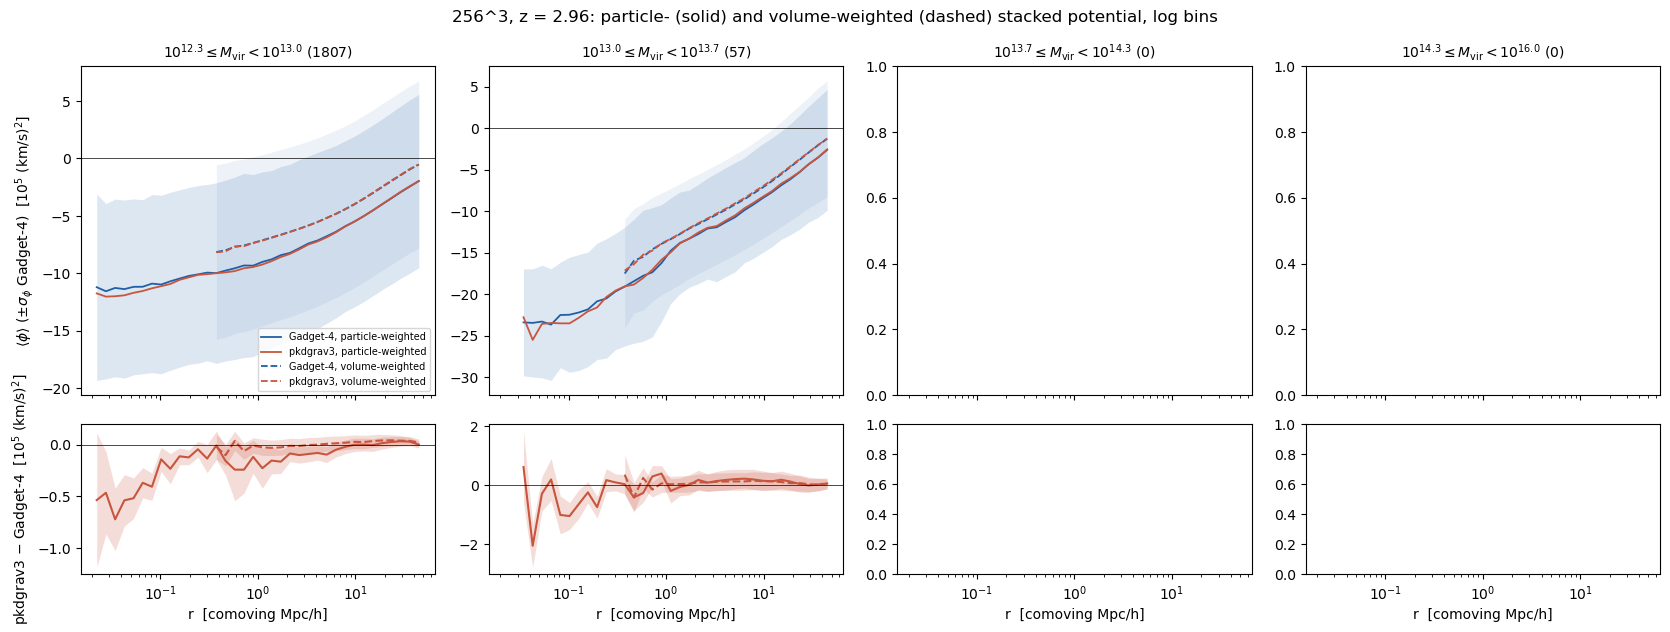

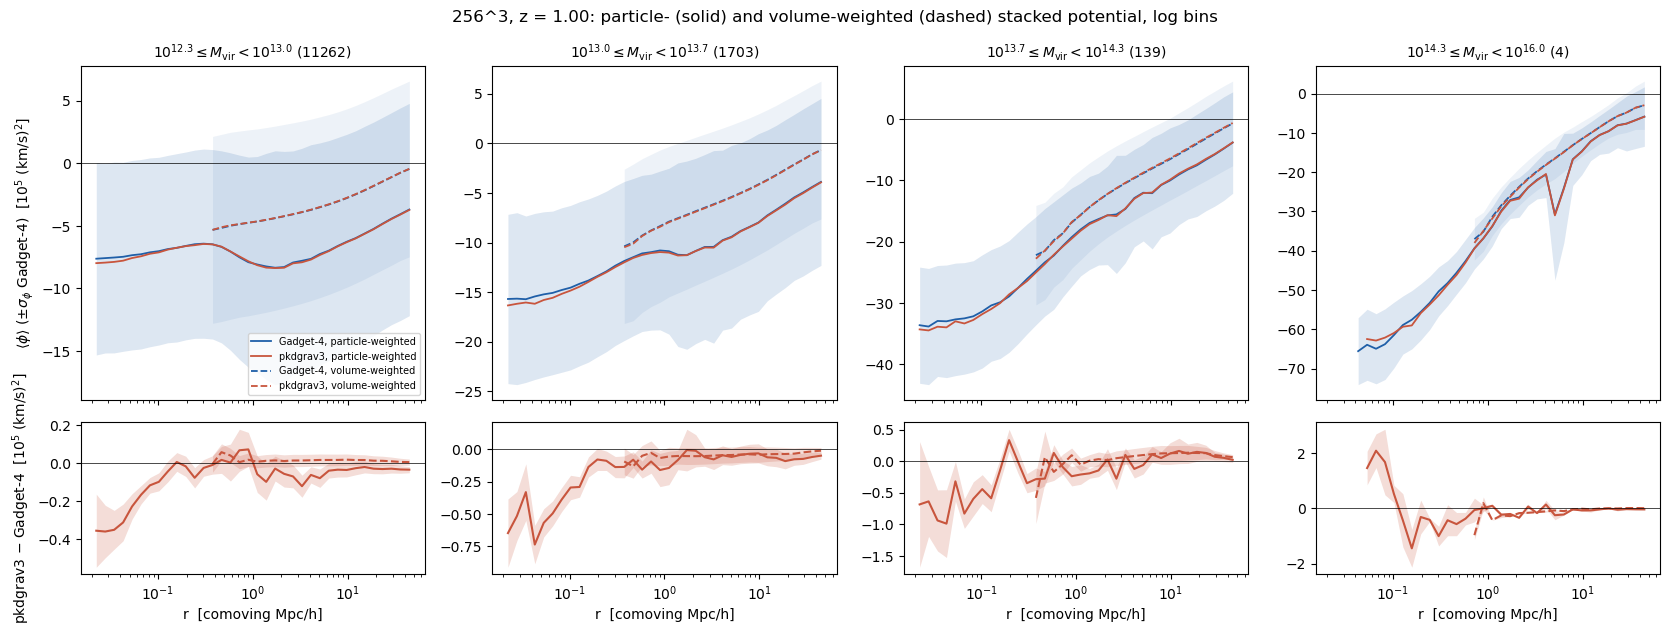

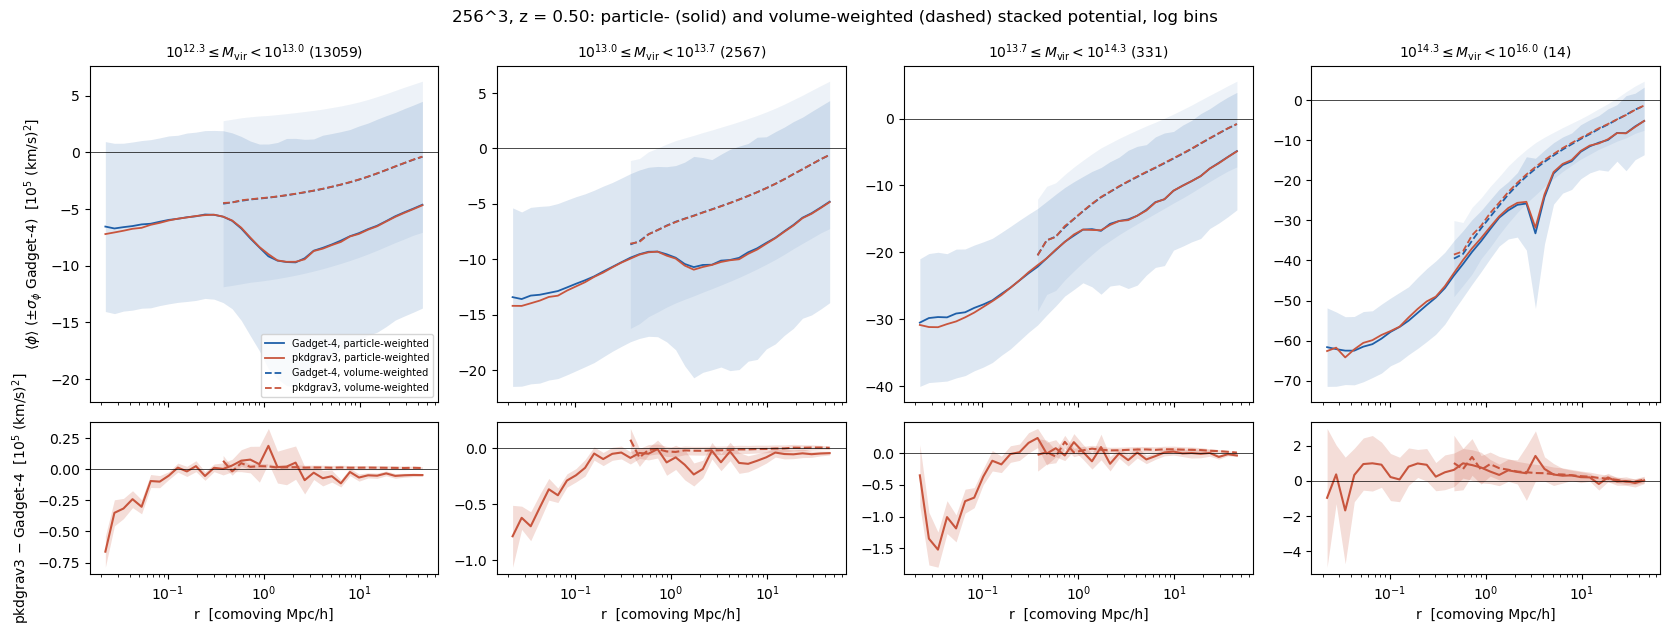

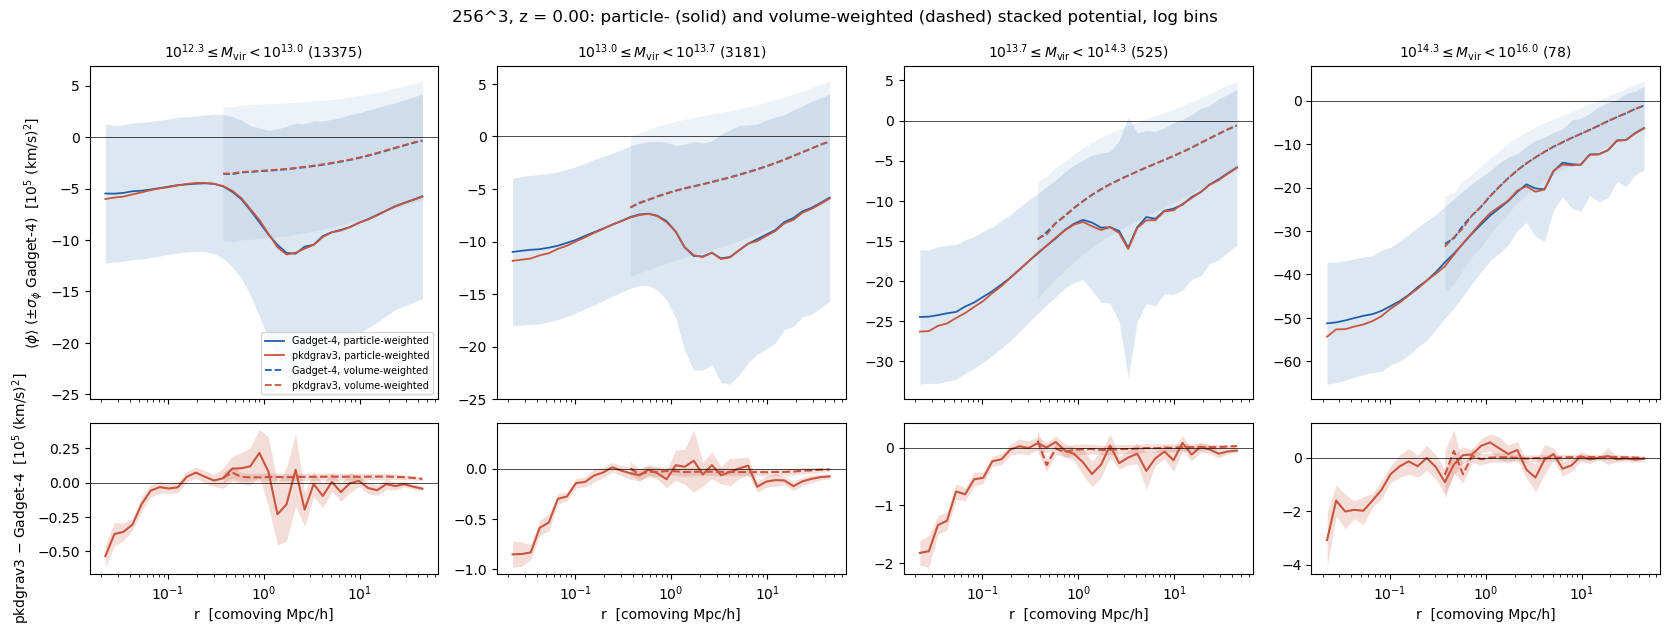

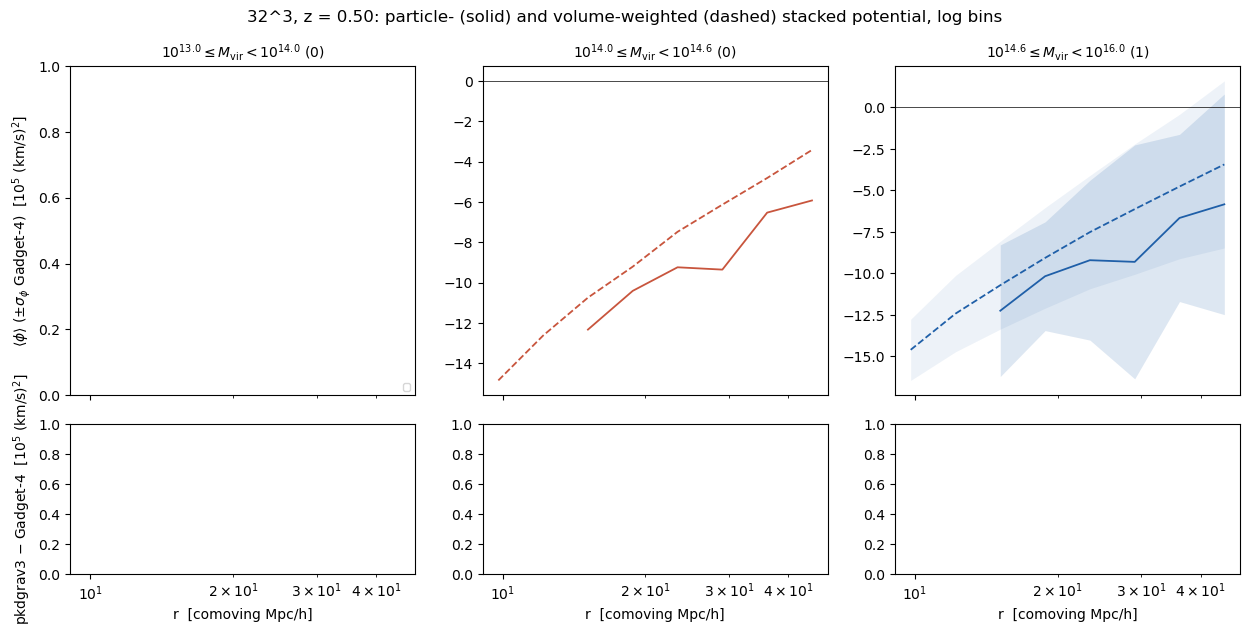

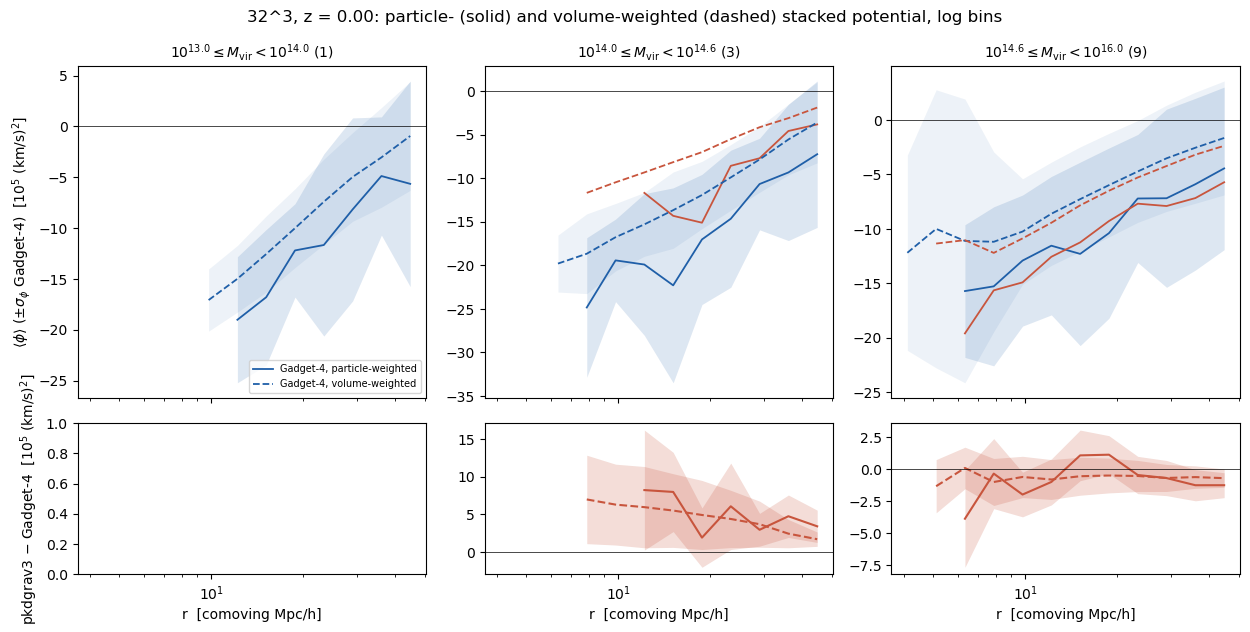

In [4]:
def plot_weights(run, i, tag='', save=True):
    S = P[run][i]
    if 'gadget_vol' + tag not in S:
        return None
    g = S['gadget' + tag]; nb = len(g['n_halos'])
    fig, ax = plt.subplots(2, nb, figsize=(4.2 * nb, 6.4), sharex=True, squeeze=False,
                           gridspec_kw=dict(height_ratios=[2.2, 1]))
    for b in range(nb):
        a0, a1 = ax[0, b], ax[1, b]
        for key, lab, col, ls in (('gadget' + tag, 'Gadget-4, particle-weighted', STYLE['gadget']['color'], '-'),
                                  ('pkd' + tag, 'pkdgrav3, particle-weighted', STYLE['pkd']['color'], '-'),
                                  ('gadget_vol' + tag, 'Gadget-4, volume-weighted', STYLE['gadget']['color'], '--'),
                                  ('pkd_vol' + tag, 'pkdgrav3, volume-weighted', STYLE['pkd']['color'], '--')):
            s = S[key]
            if s['n_halos'][b] == 0:
                continue
            m, sd = s['stack_mean'][b] / 1e5, s['stack_std'][b] / 1e5
            a0.plot(s['r_mid'], m, color=col, ls=ls, lw=1.3, label=lab)
            if key.startswith('gadget'):
                a0.fill_between(s['r_mid'], m - sd, m + sd, color=col, alpha=0.08 if 'vol' in key else 0.15, lw=0)
        for key, col, ls in (('', STYLE['pkd']['color'], '-'), ('_vol', STYLE['pkd']['color'], '--')):
            gg, pp = S['gadget' + key + tag], S['pkd' + key + tag]
            if gg['n_halos'][b] and pp['n_halos'][b]:
                d, e = jk_pair(gg, pp, b)
                a1.plot(gg['r_mid'], d / 1e5, color=col, ls=ls)
                a1.fill_between(gg['r_mid'], (d - e) / 1e5, (d + e) / 1e5, color=col, alpha=0.2, lw=0)
        a0.axhline(0, color='k', lw=0.5); a1.axhline(0, color='k', lw=0.5)
        a0.set_title(mlabel(g['m_edges'][b], g['m_edges'][b + 1]) + ' (%d)' % g['n_halos'][b], fontsize=10)
        if tag == '':
            a1.set_xscale('log')
        a1.set_xlabel('r  [comoving Mpc/h]')
    ax[0, 0].legend(fontsize=7, loc='lower right')
    ax[0, 0].set_ylabel(r'$\langle\phi\rangle$ ($\pm\sigma_\phi$ Gadget-4)  [$10^5$ (km/s)$^2$]')
    ax[1, 0].set_ylabel(r'pkdgrav3 $-$ Gadget-4  [$10^5$ (km/s)$^2$]')
    fig.suptitle('%s, z = %.2f: particle- (solid) and volume-weighted (dashed) stacked potential, %s bins'
                 % (run, float(g['z']), 'log' if tag == '' else 'linear 0.2 Mpc/h'))
    fig.tight_layout()
    if save:
        fig.savefig(os.path.join(FIGS, 'stack%s_w_%s_out%03d.pdf' % (tag, run.replace('^3', ''), i)))
    return fig

for run in P:
    for i in sorted(P[run]):
        if any(P[run][i]['gadget']['n_halos']):
            plot_weights(run, i)
plt.show()

## Linear bins: 0 to 50 Mpc/h in steps of 0.2 Mpc/h, both weightings

The same stacks in 250 linear shells (`--rbins lin:0,50,0.2`). The first shell (0-0.2 Mpc/h) holds the whole inner
halo, so the small-scale code difference seen in the log bins is averaged into it.

/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:42: RuntimeWarning: invalid value encountered in divide
  return sm / n
/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:57: RuntimeWarning: Mean of empty slice
  return full, np.sqrt((len(reg) - 1) / len(reg) * np.nansum((sub - np.nanmean(sub, 0))**2, 0))


/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:42: RuntimeWarning: invalid value encountered in divide
  return sm / n
/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:57: RuntimeWarning: Mean of empty slice
  return full, np.sqrt((len(reg) - 1) / len(reg) * np.nansum((sub - np.nanmean(sub, 0))**2, 0))


/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:42: RuntimeWarning: invalid value encountered in divide
  return sm / n
/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:57: RuntimeWarning: Mean of empty slice
  return full, np.sqrt((len(reg) - 1) / len(reg) * np.nansum((sub - np.nanmean(sub, 0))**2, 0))


/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:42: RuntimeWarning: invalid value encountered in divide
  return sm / n
/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:57: RuntimeWarning: Mean of empty slice
  return full, np.sqrt((len(reg) - 1) / len(reg) * np.nansum((sub - np.nanmean(sub, 0))**2, 0))


/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3726479351.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[0, 0].legend(fontsize=7, loc='lower right')
/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:42: RuntimeWarning: invalid value encountered in divide
  return sm / n
/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:57: RuntimeWarning: Mean of empty slice
  return full, np.sqrt((len(reg) - 1) / len(reg) * np.nansum((sub - np.nanmean(sub, 0))**2, 0))


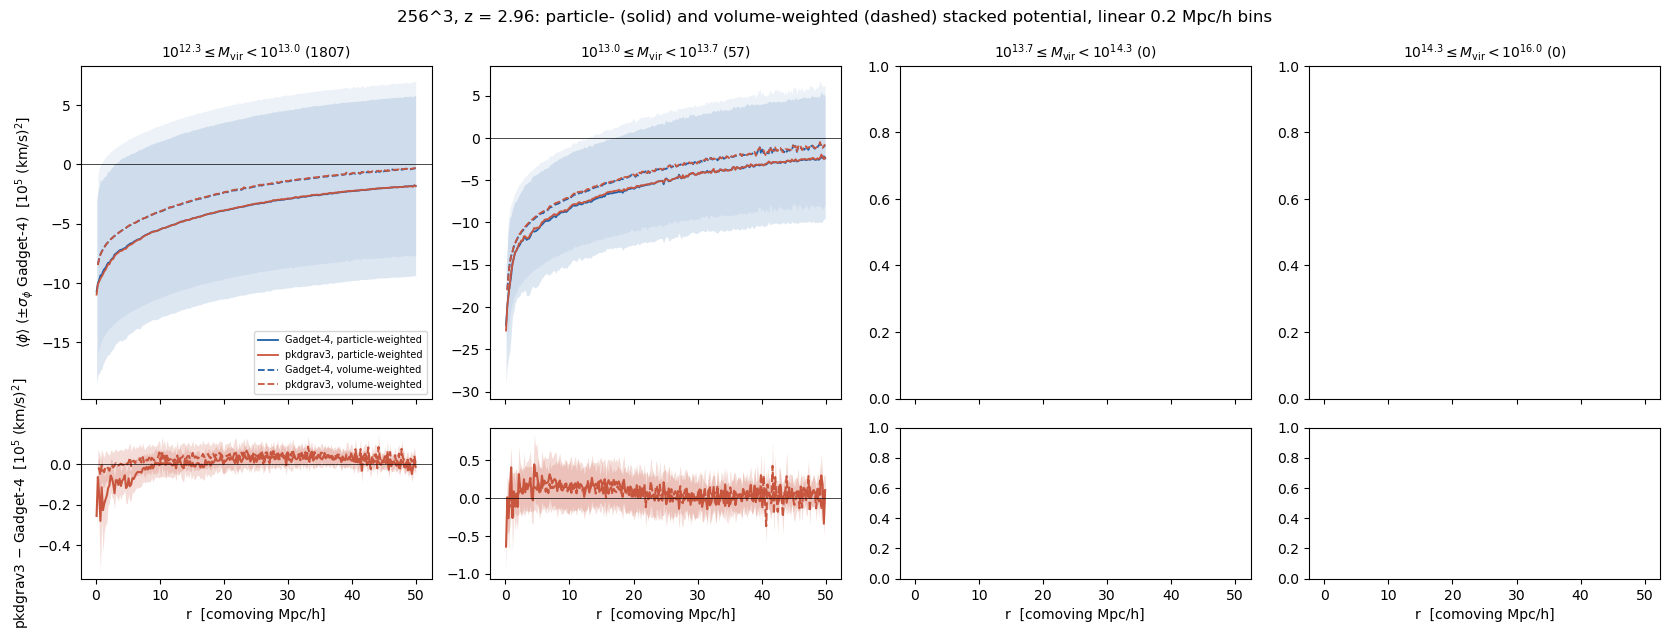

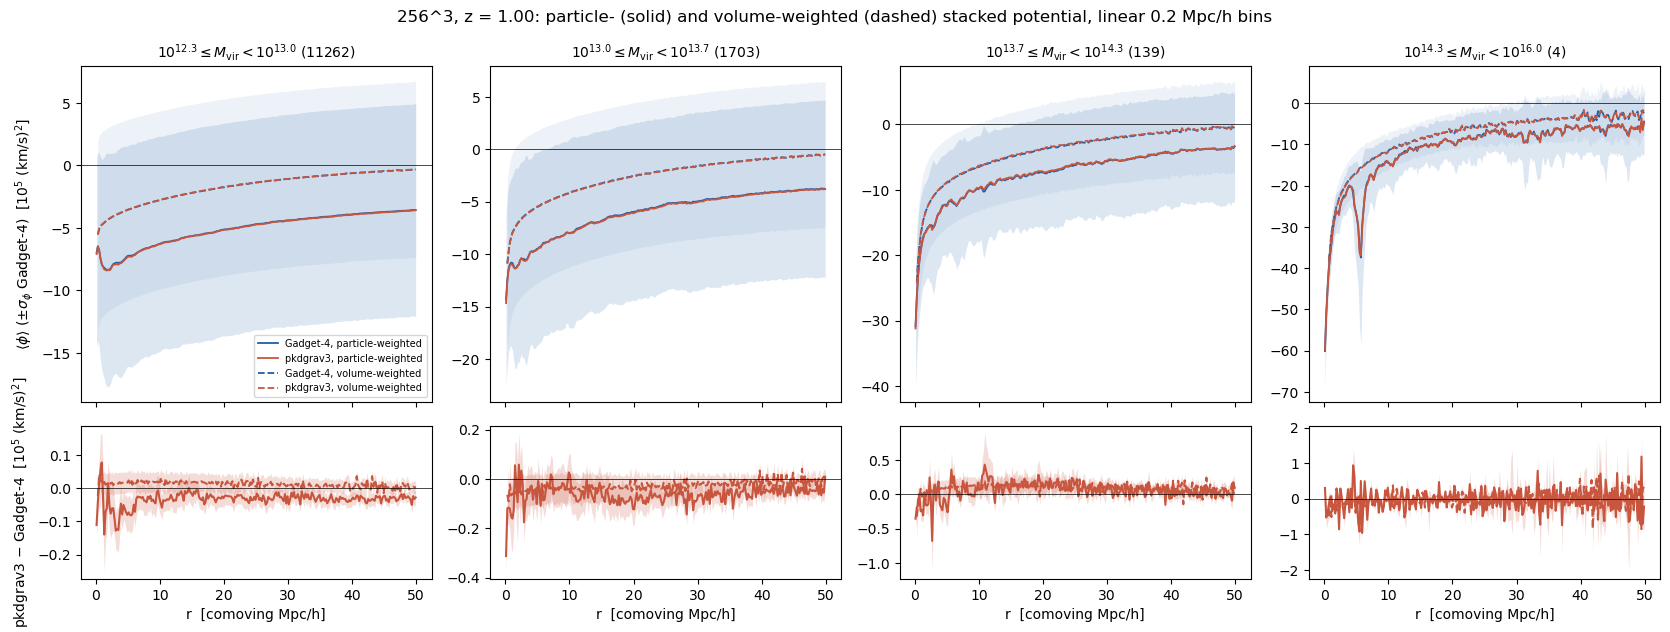

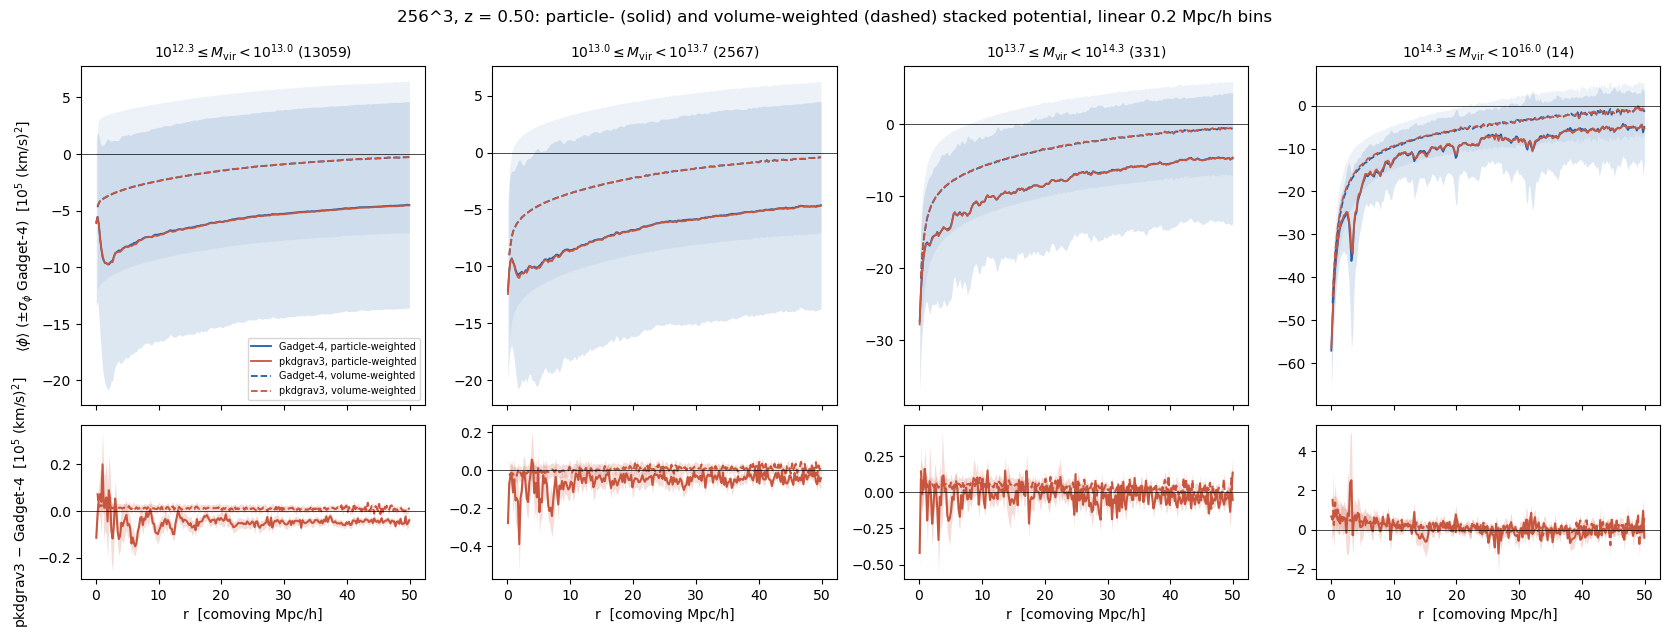

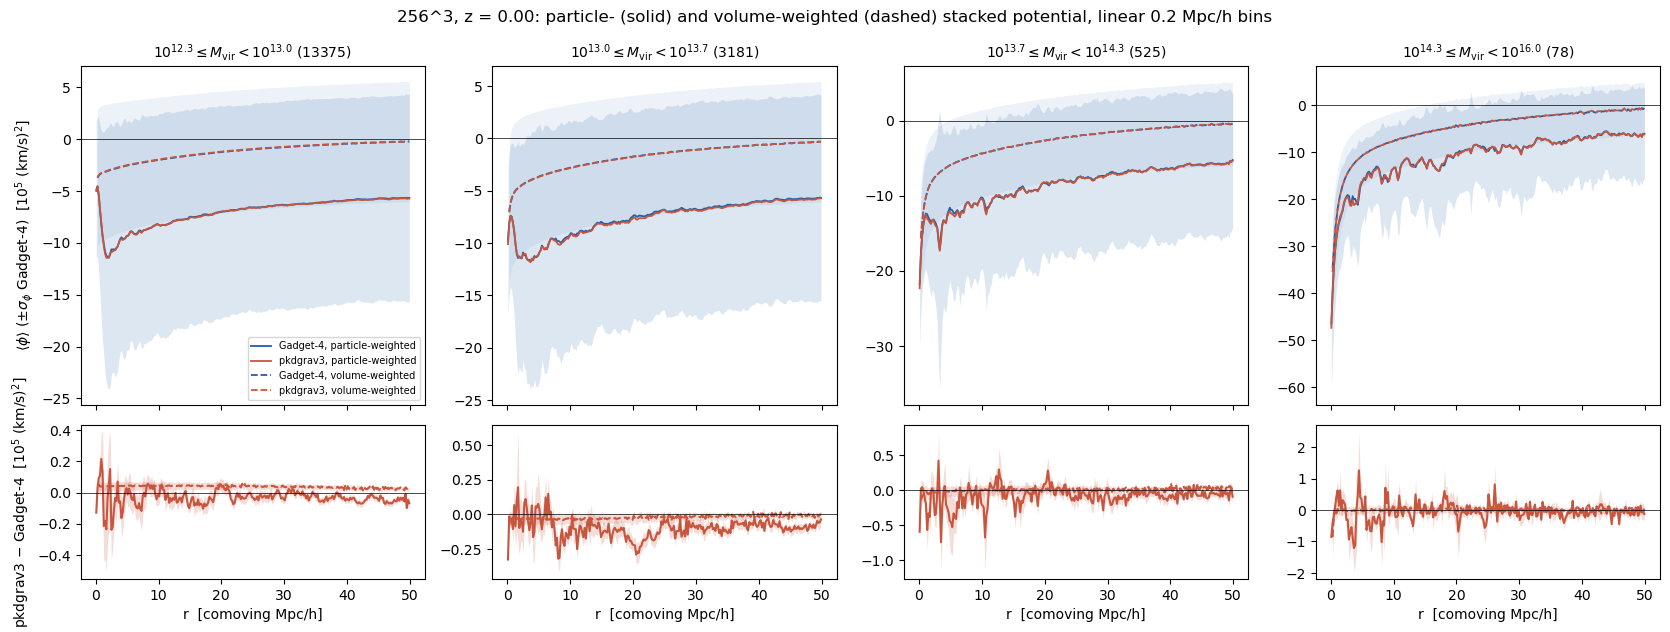

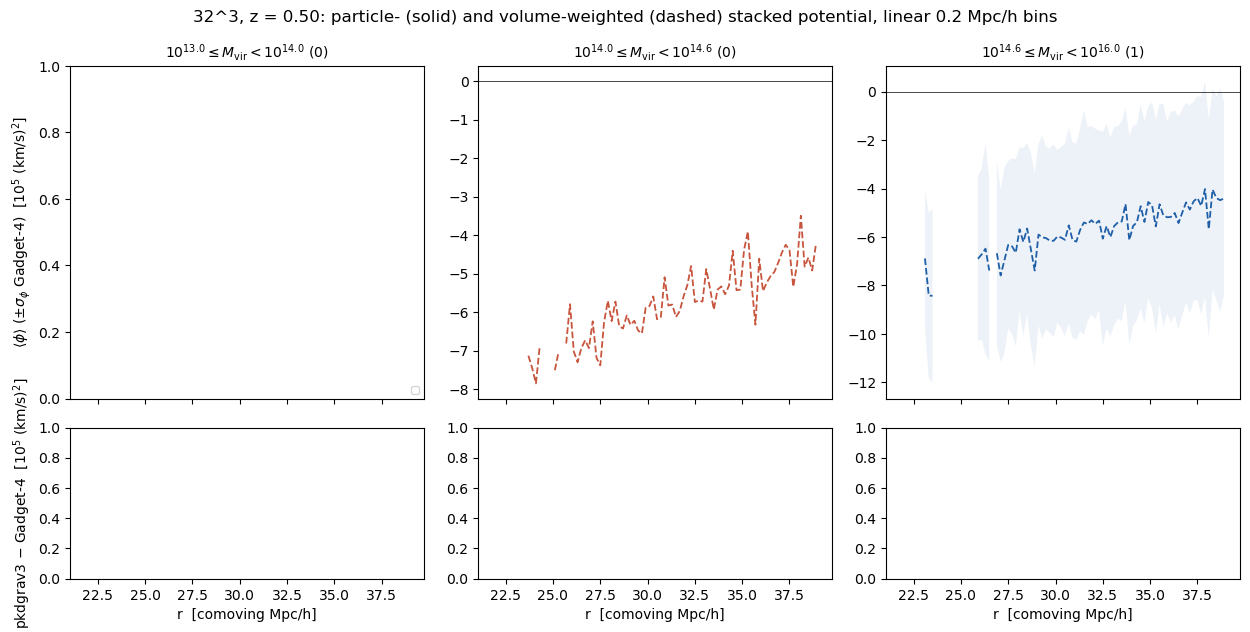

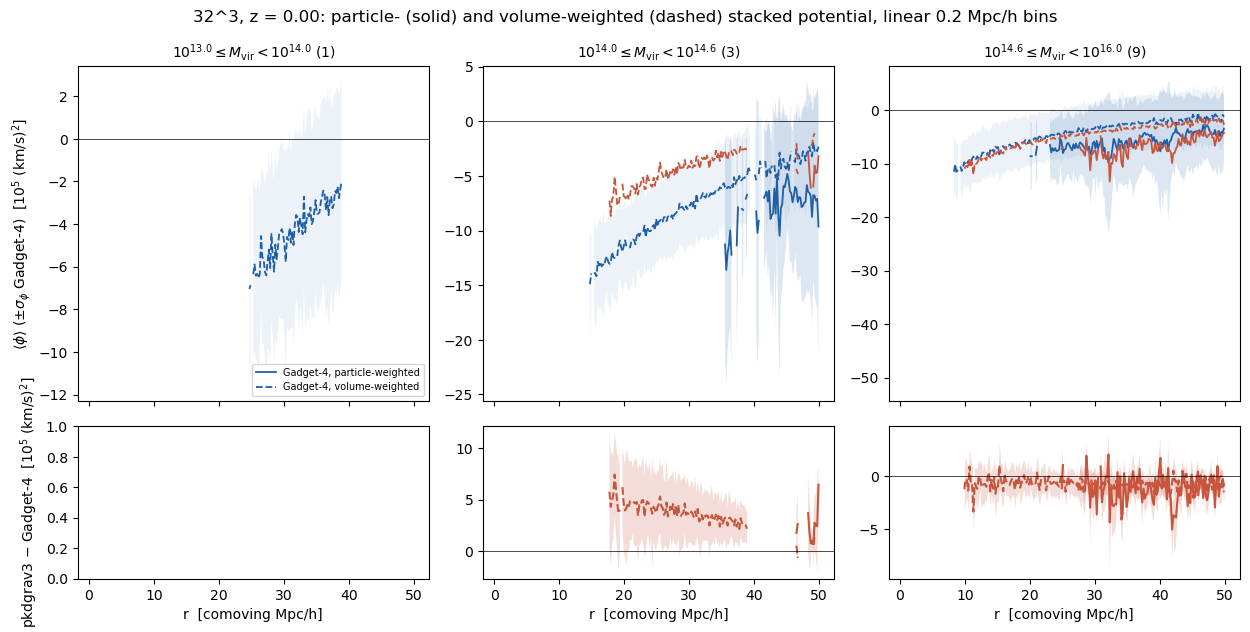

In [5]:
for run in P:
    for i in sorted(P[run]):
        if any(P[run][i]['gadget']['n_halos']):
            plot_weights(run, i, tag='_lin')
plt.show()

### Table: particle- and volume-weighted means and their code difference (linear bins, selected radii)

Rows: Gadget-4 shell means and scatters for both weightings; `d*/err` = (pkdgrav3 - Gadget-4) over its paired
jackknife error; `d*/sig` = the same difference over the Gadget-4 halo-to-halo scatter. Mass bins with fewer than
10 halos are skipped (a 3^3 jackknife is meaningless there).

In [6]:
for run in P:
    for i in sorted(P[run]):
        S = P[run][i]
        if 'gadget_vol_lin' not in S or not any(S['gadget_lin']['n_halos']):
            continue
        gl, pl, gv, pv = S['gadget_lin'], S['pkd_lin'], S['gadget_vol_lin'], S['pkd_vol_lin']
        for b in range(len(gl['n_halos'])):
            if gl['n_halos'][b] < 10:
                continue
            dp, ep = jk_pair(gl, pl, b); dv, ev = jk_pair(gv, pv, b)
            pick = [np.argmin(abs(gl['r_mid'] - r0)) for r0 in (0.1, 0.5, 1.1, 2.1, 5.1, 10.1, 20.1, 45.1)]
            print('%-6s z=%.2f %s N=%d' % (run, float(gl['z']), mlabel(gl['m_edges'][b], gl['m_edges'][b + 1]), gl['n_halos'][b]))
            print('   r          ' + ' '.join('%9.1f' % gl['r_mid'][k] for k in pick))
            print('   <phi>_part ' + ' '.join('%9.3g' % gl['stack_mean'][b][k] for k in pick))
            print('   <phi>_vol  ' + ' '.join('%9.3g' % gv['stack_mean'][b][k] for k in pick))
            print('   sig_part   ' + ' '.join('%9.3g' % gl['stack_std'][b][k] for k in pick))
            print('   sig_vol    ' + ' '.join('%9.3g' % gv['stack_std'][b][k] for k in pick))
            print('   dpart/err  ' + ' '.join('%9.2f' % (dp[k] / ep[k]) for k in pick))
            print('   dvol/err   ' + ' '.join('%9.2f' % (dv[k] / ev[k]) for k in pick))
            print('   dpart/sig  ' + ' '.join('%9.4f' % (dp[k] / gl['stack_std'][b][k]) for k in pick))
            print('   dvol/sig   ' + ' '.join('%9.4f' % (dv[k] / gv['stack_std'][b][k]) for k in pick))

256^3  z=2.96 $10^{12.3} \leq M_{\rm vir} < 10^{13.0}$ N=1807
   r                0.1       0.5       1.1       2.1       5.1      10.1      20.1      45.1
   <phi>_part -1.07e+06 -9.74e+05 -9.04e+05 -8.32e+05 -6.78e+05 -5.47e+05 -3.87e+05 -2.01e+05
   <phi>_vol        nan -7.93e+05 -7.14e+05 -6.42e+05 -5.21e+05 -3.95e+05 -2.36e+05 -5.36e+04
   sig_part    7.74e+05  7.89e+05  7.83e+05  7.72e+05  7.53e+05  7.43e+05  7.44e+05  7.56e+05
   sig_vol          nan  7.57e+05  7.44e+05  7.39e+05  7.31e+05  7.27e+05  7.26e+05  7.27e+05
   dpart/err      -3.90     -0.83     -1.10     -1.20     -0.92      0.08      0.17      0.24
   dvol/err         nan     -0.28     -0.41     -0.46      0.13     -0.04      0.43      0.81
   dpart/sig    -0.0331   -0.0186   -0.0291   -0.0137   -0.0095    0.0007    0.0013    0.0012
   dvol/sig         nan   -0.0029   -0.0045   -0.0046    0.0013   -0.0004    0.0040    0.0051
256^3  z=2.96 $10^{13.0} \leq M_{\rm vir} < 10^{13.7}$ N=57
   r                0.1       0.

/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:42: RuntimeWarning: invalid value encountered in divide
  return sm / n
/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:57: RuntimeWarning: Mean of empty slice
  return full, np.sqrt((len(reg) - 1) / len(reg) * np.nansum((sub - np.nanmean(sub, 0))**2, 0))


## Matter overdensity around the same halos (halo-matter cross-correlation)

The pair counts of the same stacks give $1+\xi_{hm}(r)$; differences here show where the two codes put the mass.

/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:47: RuntimeWarning: invalid value encountered in divide
  f = (lambda a, c: c - a) if what == 'phi' else (lambda a, c: c / a - 1)
/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:57: RuntimeWarning: Mean of empty slice
  return full, np.sqrt((len(reg) - 1) / len(reg) * np.nansum((sub - np.nanmean(sub, 0))**2, 0))


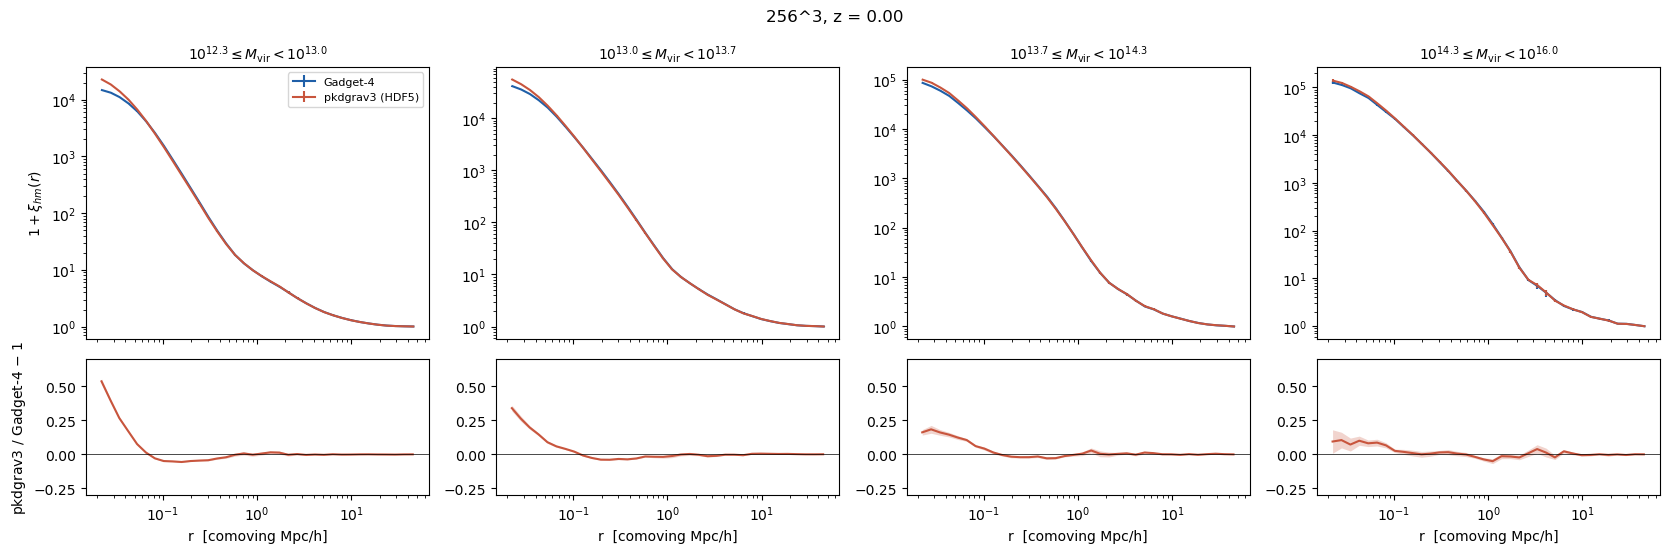

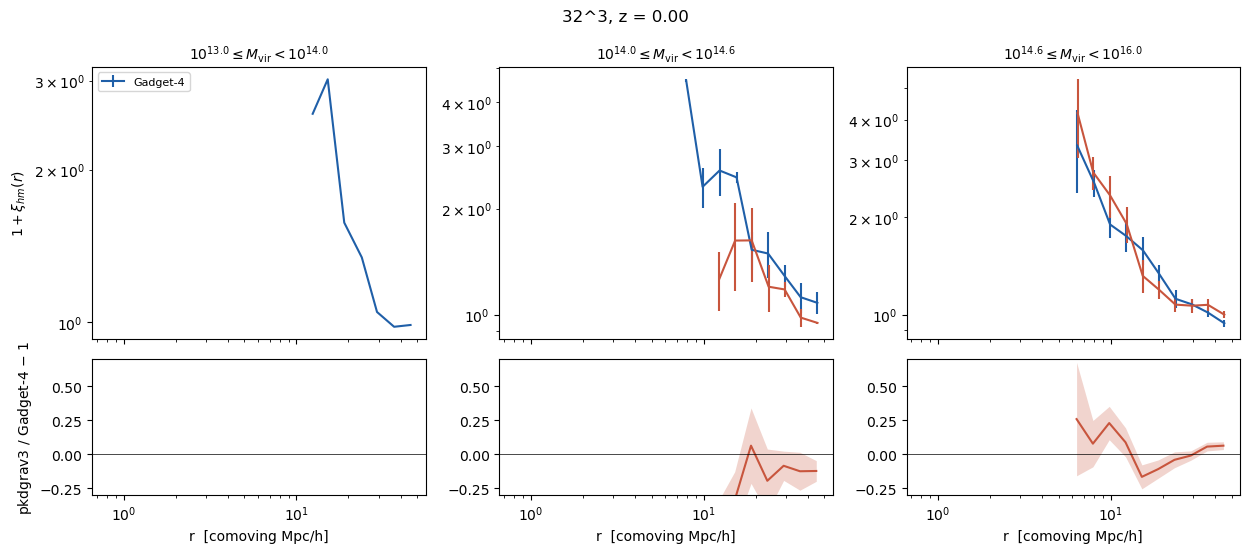

In [7]:
def plot_delta(run, save=True):
    outs = [i for i in sorted(P[run]) if any(P[run][i]['gadget']['n_halos'])]
    i = outs[-1]; S = P[run][i]; g = S['gadget']; nb = len(g['n_halos'])
    fig, ax = plt.subplots(2, nb, figsize=(4.2 * nb, 5.6), squeeze=False, sharex=True,
                           gridspec_kw=dict(height_ratios=[2, 1]))
    for b in range(nb):
        if g['n_halos'][b] and S['pkd']['n_halos'][b]:
            d, e = jk_pair(g, S['pkd'], b, 'xi')
            ax[1, b].plot(g['r_mid'], d, color=STYLE['pkd']['color'])
            ax[1, b].fill_between(g['r_mid'], d - e, d + e, color=STYLE['pkd']['color'], alpha=0.25, lw=0)
        ax[1, b].axhline(0, color='k', lw=0.5); ax[1, b].set_ylim(-0.3, 0.7)
        ax[1, b].set_xlabel('r  [comoving Mpc/h]')
        for kind in ('gadget', 'pkd'):
            s = S[kind]
            if s['n_halos'][b] == 0:
                continue
            ax[0, b].errorbar(s['r_mean'][b], 1 + s['delta_hm'][b], s['delta_hm_err'][b], color=STYLE[kind]['color'],
                              label=STYLE[kind]['label'], capsize=0)
        ax[0, b].set_xscale('log'); ax[0, b].set_yscale('log')
        ax[0, b].set_title(mlabel(g['m_edges'][b], g['m_edges'][b + 1]), fontsize=10)
    ax[0, 0].set_ylabel(r'$1 + \xi_{hm}(r)$'); ax[0, 0].legend(fontsize=8)
    ax[1, 0].set_ylabel('pkdgrav3 / Gadget-4 $-$ 1')
    fig.suptitle('%s, z = %.2f' % (run, float(g['z']))); fig.tight_layout()
    if save:
        fig.savefig(os.path.join(FIGS, 'xihm_%s.pdf' % run.replace('^3', '')))
    return fig

for run in P:
    plot_delta(run)
plt.show()

## Table: mean potential difference at a few radii (pkdgrav3 HDF5 vs Gadget-4), relative and in units of $\sigma_\phi$

In [8]:
for run in P:
    for i in sorted(P[run]):
        g, p = P[run][i]['gadget'], P[run][i]['pkd']
        for b in range(len(g['n_halos'])):
            if g['n_halos'][b] == 0 or p['n_halos'][b] == 0:
                continue
            rel = p['stack_mean'][b] / g['stack_mean'][b] - 1
            dd, de = jk_pair(g, p, b)
            ds = dd / g['stack_std'][b]
            pick = [np.nanargmin(abs(g['r_mid'] - r0)) for r0 in (0.05, 0.2, 1, 5, 20, 45)]
            print('%-6s z=%.2f  %s  N=%5d/%5d  ' % (run, float(g['z']), mlabel(g['m_edges'][b], g['m_edges'][b+1]),
                  g['n_halos'][b], p['n_halos'][b]) + '  '.join('r=%.2g: %+.3f (%+.3f sig, %.1f err)' % (g['r_mid'][k], rel[k], ds[k], dd[k] / de[k]) for k in pick))

256^3  z=2.96  $10^{12.3} \leq M_{\rm vir} < 10^{13.0}$  N= 1807/ 1786  r=0.053: +0.046 (-0.068 sig, -2.6 err)  r=0.2: +0.012 (-0.016 sig, -1.7 err)  r=0.9: +0.013 (-0.015 sig, -0.7 err)  r=5.1: +0.014 (-0.013 sig, -1.3 err)  r=19: -0.004 (+0.002 sig, 0.2 err)  r=45: -0.000 (+0.000 sig, 0.0 err)
256^3  z=2.96  $10^{13.0} \leq M_{\rm vir} < 10^{13.7}$  N=   57/   54  r=0.053: +0.012 (-0.042 sig, -0.5 err)  r=0.2: +0.035 (-0.105 sig, -2.0 err)  r=0.9: -0.025 (+0.057 sig, 1.5 err)  r=5.1: -0.020 (+0.032 sig, 0.6 err)  r=19: -0.021 (+0.019 sig, 0.4 err)  r=45: -0.025 (+0.009 sig, 0.4 err)
256^3  z=1.00  $10^{12.3} \leq M_{\rm vir} < 10^{13.0}$  N=11262/11296  r=0.053: +0.031 (-0.030 sig, -3.4 err)  r=0.2: +0.002 (-0.002 sig, -0.3 err)  r=0.9: -0.009 (+0.009 sig, 0.8 err)  r=5.1: +0.011 (-0.009 sig, -1.6 err)  r=19: +0.005 (-0.003 sig, -1.1 err)  r=45: +0.009 (-0.004 sig, -2.0 err)
256^3  z=1.00  $10^{13.0} \leq M_{\rm vir} < 10^{13.7}$  N= 1703/ 1716  r=0.053: +0.037 (-0.068 sig, -5.2 err)

/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:42: RuntimeWarning: invalid value encountered in divide
  return sm / n
/var/folders/k_/jbvyg2ks1xv24y_9ry4ybkmr0000gp/T/ipykernel_57726/3943196147.py:57: RuntimeWarning: Mean of empty slice
  return full, np.sqrt((len(reg) - 1) / len(reg) * np.nansum((sub - np.nanmean(sub, 0))**2, 0))
